# M50 — Ablation Study

## AuthentiScore

This experiment evaluates the contribution of different feature groups to the AuthentiScore Random Forest classifier.

### Feature Groups
- **Audience:** followers, following, follower_following_ratio
- **Activity:** posts
- **Profile:** bio_length, has_profile_picture, is_private, profile_completeness
- **Username:** username_digit_ratio

### Experiments
1. Baseline — all features
2. Without Audience features
3. Without Activity features
4. Without Profile features
5. Without Username features

The same train/test split is used for every experiment.

**NLP limitation:** the current feature dataset contains `bio_length` but not original bio text, so a quantitative NLP-text ablation is not performed here.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import matplotlib.pyplot as plt

In [2]:
CURRENT_DIR = Path.cwd()
possible_roots = [CURRENT_DIR, CURRENT_DIR.parent, CURRENT_DIR.parent.parent]
PROJECT_ROOT = next((r for r in possible_roots if (r / "data").exists() and (r / "backend").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate AuthentiScore project root.")
print("Project root:", PROJECT_ROOT)

Project root: c:\Users\Acer\Documents\AuthentiScore


In [3]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
DATASET_PATH = PROCESSED_DIR / "instagram_features.csv"
if not DATASET_PATH.exists():
    raise FileNotFoundError(f"instagram_features.csv not found at:\n{DATASET_PATH}")
print("Dataset:", DATASET_PATH)

Dataset: c:\Users\Acer\Documents\AuthentiScore\data\processed\instagram_features.csv


In [4]:
df = pd.read_csv(DATASET_PATH)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (696, 10)
Columns: ['followers', 'following', 'posts', 'bio_length', 'has_profile_picture', 'is_private', 'username_digit_ratio', 'fake', 'follower_following_ratio', 'profile_completeness']


,followers,following,posts,bio_length,has_profile_picture,is_private,username_digit_ratio,fake,follower_following_ratio,profile_completeness
0,1000,955,32,53,1,0,0.27,0,1.047120,1.0
1,2740,533,286,44,1,0,0.00,0,5.140713,1.0
2,159,98,13,0,1,1,0.10,0,1.622449,1.0
3,414,651,679,82,1,0,0.00,0,0.635945,1.0
4,151,126,6,0,1,1,0.00,0,1.198413,1.0


In [5]:
possible_label_columns = ["label", "is_fake", "fake", "target", "class"]
label_column = next((c for c in possible_label_columns if c in df.columns), None)
if label_column is None:
    raise ValueError(f"Could not find label column. Available columns: {df.columns.tolist()}")
print("Label column:", label_column)
print(df[label_column].value_counts())

Label column: fake
fake
0    348
1    348
Name: count, dtype: int64


In [6]:
FEATURE_COLUMNS = ["followers", "following", "posts", "bio_length", "has_profile_picture", "is_private", "username_digit_ratio", "follower_following_ratio", "profile_completeness"]
missing = [f for f in FEATURE_COLUMNS if f not in df.columns]
if missing:
    raise ValueError("Missing AuthentiScore features: " + ", ".join(missing))
FEATURE_GROUPS = {
    "Audience": ["followers", "following", "follower_following_ratio"],
    "Activity": ["posts"],
    "Profile": ["bio_length", "has_profile_picture", "is_private", "profile_completeness"],
    "Username": ["username_digit_ratio"]
}
print("✓ All 9 features are present")

✓ All 9 features are present


In [7]:
X = df[FEATURE_COLUMNS].copy()
y = df[label_column].copy()
for c in FEATURE_COLUMNS:
    X[c] = pd.to_numeric(X[c], errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan).fillna(0)
labels = sorted(y.dropna().unique().tolist(), key=lambda v: str(v))
if set(labels).issubset({0, 1}):
    y_binary = y.astype(int)
elif set(labels).issubset({False, True}):
    y_binary = y.astype(int)
else:
    if len(labels) != 2: raise ValueError(f"Expected binary labels, found {labels}")
    y_binary = y.map({labels[0]: 0, labels[1]: 1}).astype(int)
print("X:", X.shape, "y:", y_binary.shape)
print(y_binary.value_counts())

X: (696, 9) y: (696,)
fake
0    348
1    348
Name: count, dtype: int64


In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y_binary, test_size=0.20, random_state=42, stratify=y_binary)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 556
Testing samples: 140


In [9]:
def evaluate_model(feature_list, experiment_name):
    model = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
    model.fit(X_train[feature_list], y_train)
    pred = model.predict(X_test[feature_list])
    prob = model.predict_proba(X_test[feature_list])[:, 1]
    return {
        "experiment": experiment_name,
        "features": len(feature_list),
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, prob),
        "feature_list": feature_list,
        "model": model
    }

In [10]:
results = [evaluate_model(FEATURE_COLUMNS, "Baseline — All Features")]
for group, group_features in FEATURE_GROUPS.items():
    remaining = [f for f in FEATURE_COLUMNS if f not in group_features]
    results.append(evaluate_model(remaining, f"Without {group}"))
results_df = pd.DataFrame([{
    "Experiment": r["experiment"], "Features": r["features"], "Accuracy": r["accuracy"],
    "Precision": r["precision"], "Recall": r["recall"], "F1": r["f1"], "ROC-AUC": r["roc_auc"]
} for r in results])
display(results_df)

,Experiment,Features,Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline — All Features,9,0.892857,0.910448,0.871429,0.890511,0.964184
1,Without Audience,6,0.828571,0.859375,0.785714,0.820896,0.925510
2,Without Activity,8,0.907143,0.925373,0.885714,0.905109,0.975612
3,Without Profile,5,0.871429,0.842105,0.914286,0.876712,0.941939
4,Without Username,8,0.878571,0.884058,0.871429,0.877698,0.950918


In [11]:
percentage_results = results_df.copy()
for c in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]:
    percentage_results[c] = (percentage_results[c] * 100).round(2)
display(percentage_results)

,Experiment,Features,Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline — All Features,9,89.29,91.04,87.14,89.05,96.42
1,Without Audience,6,82.86,85.94,78.57,82.09,92.55
2,Without Activity,8,90.71,92.54,88.57,90.51,97.56
3,Without Profile,5,87.14,84.21,91.43,87.67,94.19
4,Without Username,8,87.86,88.41,87.14,87.77,95.09


In [12]:
baseline = results_df.iloc[0]
change_df = results_df.copy()
for c in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]:
    change_df[f"{c}_Change_pp"] = ((change_df[c] - baseline[c]) * 100).round(2)
display(change_df[["Experiment", "Features", "Accuracy_Change_pp", "Precision_Change_pp", "Recall_Change_pp", "F1_Change_pp", "ROC-AUC_Change_pp"]])

,Experiment,Features,Accuracy_Change_pp,Precision_Change_pp,Recall_Change_pp,F1_Change_pp,ROC-AUC_Change_pp
0,Baseline — All Features,9,0.00,0.00,0.00,0.00,0.00
1,Without Audience,6,-6.43,-5.11,-8.57,-6.96,-3.87
2,Without Activity,8,1.43,1.49,1.43,1.46,1.14
3,Without Profile,5,-2.14,-6.83,4.29,-1.38,-2.22
4,Without Username,8,-1.43,-2.64,0.00,-1.28,-1.33


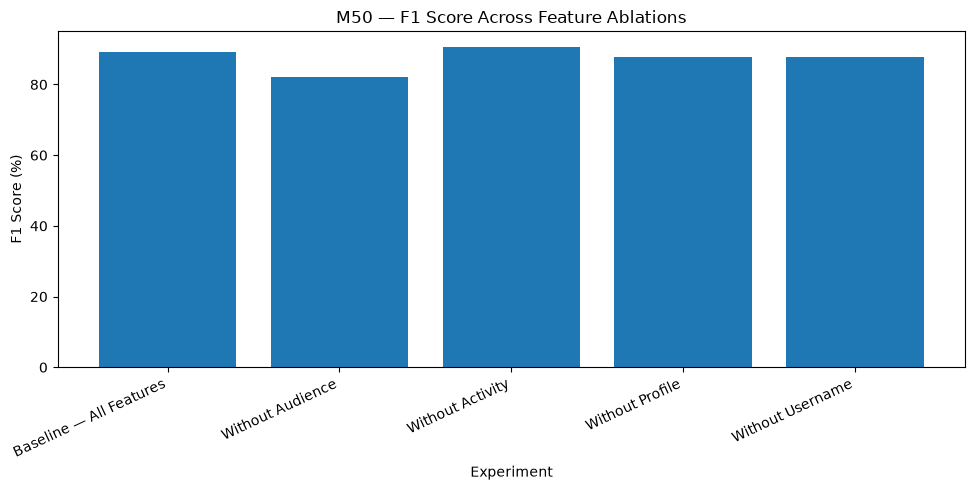

In [13]:
plt.figure(figsize=(10,5))
plt.bar(results_df["Experiment"], results_df["F1"] * 100)
plt.ylabel("F1 Score (%)")
plt.xlabel("Experiment")
plt.title("M50 — F1 Score Across Feature Ablations")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

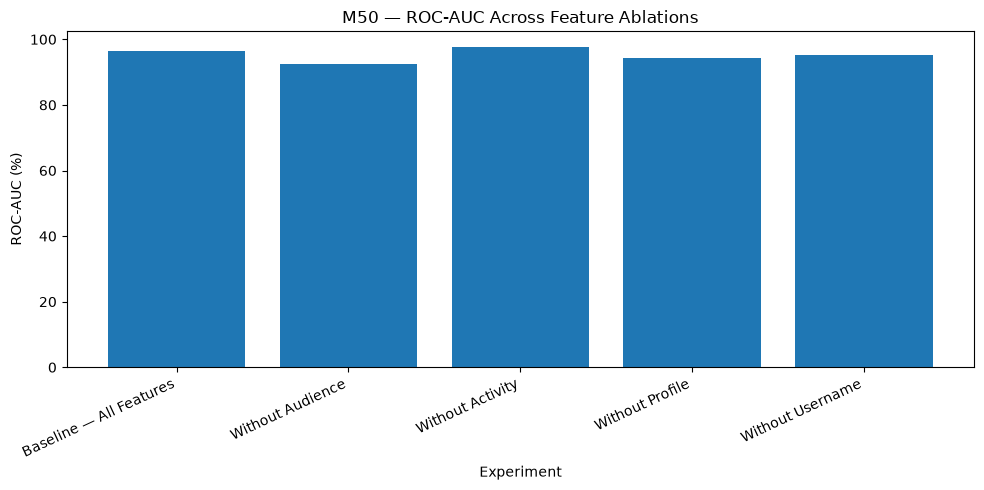

In [14]:
plt.figure(figsize=(10,5))
plt.bar(results_df["Experiment"], results_df["ROC-AUC"] * 100)
plt.ylabel("ROC-AUC (%)")
plt.xlabel("Experiment")
plt.title("M50 — ROC-AUC Across Feature Ablations")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [15]:
baseline_model = results[0]["model"]
importance_df = pd.DataFrame({"Feature": FEATURE_COLUMNS, "Importance": baseline_model.feature_importances_}).sort_values("Importance", ascending=False)
display(importance_df)

,Feature,Importance
2,posts,0.285835
0,followers,0.211047
7,follower_following_ratio,0.149923
6,username_digit_ratio,0.114737
4,has_profile_picture,0.097088
3,bio_length,0.084810
1,following,0.048558
5,is_private,0.008002
8,profile_completeness,0.000000


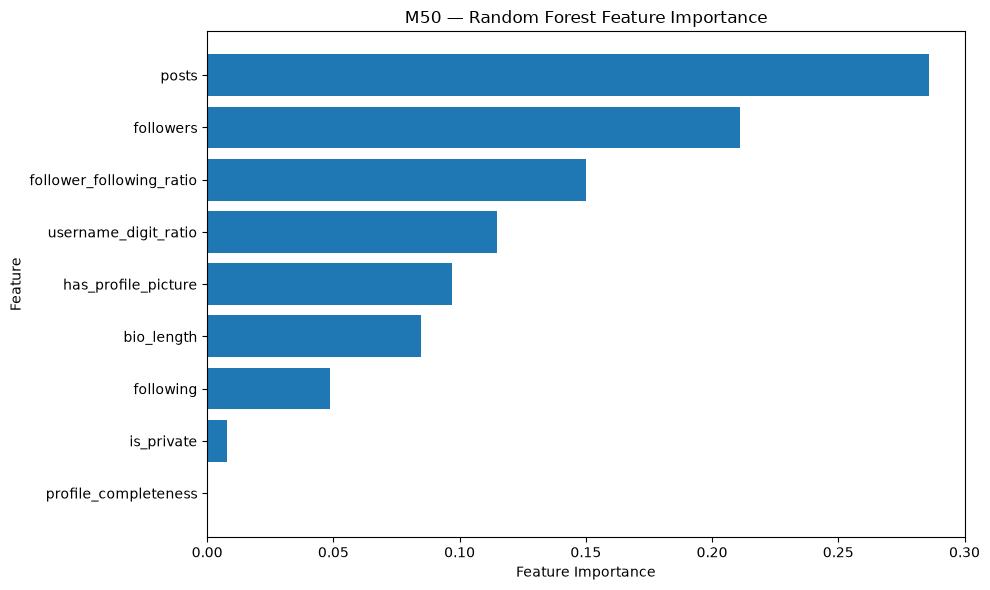

In [16]:
plt.figure(figsize=(10,6))
plt.barh(importance_df["Feature"], importance_df["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("M50 — Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [17]:
ABLATION_RESULTS_PATH = PROCESSED_DIR / "ablation_results.csv"
results_df.to_csv(ABLATION_RESULTS_PATH, index=False)
ABLATION_CHANGE_PATH = PROCESSED_DIR / "ablation_changes.csv"
change_df.to_csv(ABLATION_CHANGE_PATH, index=False)
print("✓ Saved:", ABLATION_RESULTS_PATH)
print("✓ Saved:", ABLATION_CHANGE_PATH)

✓ Saved: c:\Users\Acer\Documents\AuthentiScore\data\processed\ablation_results.csv
✓ Saved: c:\Users\Acer\Documents\AuthentiScore\data\processed\ablation_changes.csv


In [18]:
print("=" * 60)
print("M50 — ABLATION STUDY COMPLETE")
print("=" * 60)
print("\nResults:")
display(percentage_results)
print("\nNLP limitation: the current feature dataset contains bio_length but not original bio text, so quantitative NLP-text ablation was not performed.")
print("\nM50 completed.")

M50 — ABLATION STUDY COMPLETE

Results:


,Experiment,Features,Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline — All Features,9,89.29,91.04,87.14,89.05,96.42
1,Without Audience,6,82.86,85.94,78.57,82.09,92.55
2,Without Activity,8,90.71,92.54,88.57,90.51,97.56
3,Without Profile,5,87.14,84.21,91.43,87.67,94.19
4,Without Username,8,87.86,88.41,87.14,87.77,95.09



NLP limitation: the current feature dataset contains bio_length but not original bio text, so quantitative NLP-text ablation was not performed.

M50 completed.
